# AquaFlow: ciclo completo de machine learning

Este notebook complementa o pipeline de ML do AquaFlow: documenta a exploração e preparação de uma série reproduzível e, em uma seção separada, mostra gráficos dos modelos usando os resultados do treinamento já executado.

Os dados são simulados. Os rótulos representam cenários criados pelo gerador, não vazamentos confirmados. O notebook não substitui nem altera o pipeline automatizado, a API, os alertas ou o dashboard.

A unidade da avaliação é um intervalo entre leituras válidas. O rótulo indica o cenário programado no gerador. A calibração usa medições de bancada para parametrizar vazões, mas a rotina, a agenda dos cenários e os rótulos são simulados.

**Sumário**

1. Origem, exploração e preparação dos dados
2. Divisão temporal, treino e seleção
3. Avaliação, erros e mudança de rotina
4. Inferência, integração e critérios de entrega


In [1]:
from datetime import UTC, datetime
from pathlib import Path
import hashlib
import json
import sys
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import load
from sklearn.metrics import average_precision_score, confusion_matrix, precision_recall_curve, roc_auc_score, roc_curve
from zoneinfo import ZoneInfo

current = Path.cwd().resolve()
root = next((p for p in (current, *current.parents) if (p / "ml" / "train_model.py").is_file()), None)
if root is None:
    raise RuntimeError("Abra o notebook dentro do repositório AquaFlow.")
sys.path.insert(0, str(root / "ml"))
from build_real_dataset import DEFAULT_CALIBRATION, build
from prepare_dataset import analyze, prepare

DATA_DIR = root / "data" / "ml" / "notebook"
RAW_PATH = DATA_DIR / "raw" / "household_readings.csv"
PREPARED_DIR = DATA_DIR / "prepared"
FIGURES_DIR = DATA_DIR / "figures"
TRAINING_DIR = root / os.getenv("AQUAFLOW_NOTEBOOK_TRAINING_DIR", "data/ml/training-bench-v2")
TIMEZONE = "America/Sao_Paulo"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.2})
pd.set_option("display.max_columns", 20)


## 1. Geração, análise e preparação

A série usa seed fixa, intervalo de cinco minutos e fuso local da propriedade. O pipeline valida registros, mantém features separadas dos rótulos e aplica as mesmas transformações determinísticas usadas no treino e na inferência.

In [2]:
build(None, RAW_PATH, calibration=DEFAULT_CALIBRATION, seed=42, start=datetime.fromisoformat("2026-09-01T00:00:00-03:00").astimezone(UTC), days=16, interval_minutes=5, timezone=TIMEZONE)
quality_report = analyze(RAW_PATH, DATA_DIR / "analysis")
preparation_report = prepare(RAW_PATH, PREPARED_DIR, TIMEZONE)
raw = pd.read_csv(RAW_PATH)
features = pd.read_csv(PREPARED_DIR / "features.csv")
labels = pd.read_csv(PREPARED_DIR / "labels.csv")
metadata = pd.read_csv(PREPARED_DIR / "metadata.csv")
print(f"Qualidade: {quality_report['status']} | Leituras preparadas: {preparation_report['prepared_readings']}")
print(f"Features: {', '.join(features.columns)}")
print(f"Rótulos separados: {', '.join(labels.columns)}")
raw.head()

Qualidade: passed | Leituras preparadas: 4511
Features: flow_rate_liters_minute, volume_delta_liters, elapsed_minutes, local_hour_sin, local_hour_cos, local_weekday_sin, local_weekday_cos
Rótulos separados: event_id, scenario_label, anomaly_label


,device_serial,event_id,recorded_at,cumulative_volume_liters,flow_rate_liters_minute,battery_percent,signal_dbm,firmware_version,reading_present,scenario_label,anomaly_label
0,AF-ML-MOCK-001,eb868fd9-a5cc-565d-8f40-5317aa9c0fac,2026-09-01T03:00:00Z,1000.0,0.0,95.0,-58.0,bench-sim-1,1,normal,0
1,AF-ML-MOCK-001,e04e62dc-b993-5496-930a-9d5077738cbf,2026-09-01T03:05:00Z,1000.0,0.0,95.0,-58.0,bench-sim-1,1,normal,0
2,AF-ML-MOCK-001,f6074e93-40e9-5d1f-b989-87691d2cd76c,2026-09-01T03:10:00Z,1000.0,0.0,95.0,-58.0,bench-sim-1,1,normal,0
3,AF-ML-MOCK-001,bb40ef09-192f-5b11-b12d-8f8a6b561914,2026-09-01T03:15:00Z,1000.0,0.0,95.0,-58.0,bench-sim-1,1,normal,0
4,AF-ML-MOCK-001,f7b62330-dec0-5254-ae1e-7639cae49d7d,2026-09-01T03:20:00Z,1000.0,0.0,95.0,-58.0,bench-sim-1,1,normal,0


### Origem e cobertura

A série de referência tem 16 dias e cadência nominal de cinco minutos. A tabela abaixo registra a versão exata da calibração usada. A série serve para avaliar a separação entre os cenários do gerador.

Calibração: bench-calibration-v1.json | SHA-256: 4f7676c2423dee5a88c1aa667e00522a27cb48fa77c0ec8d607b9247207d47e8


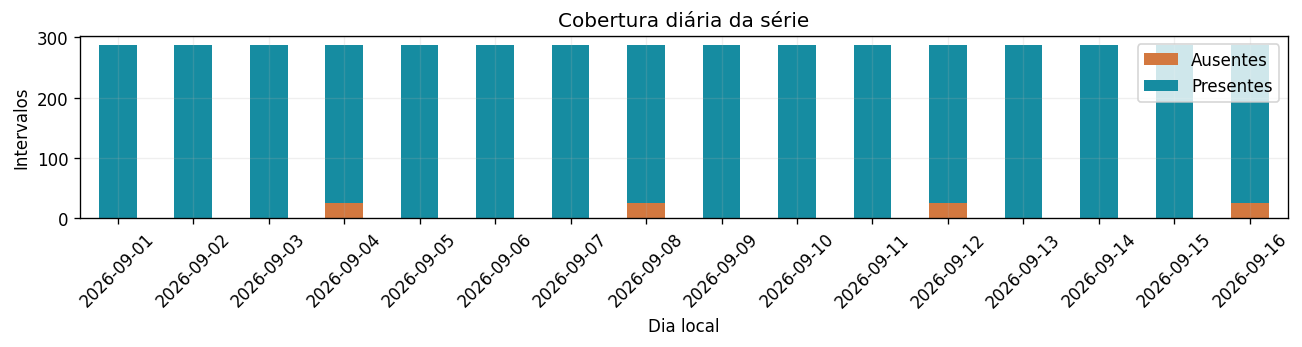

In [3]:
calibration_hash = hashlib.sha256(DEFAULT_CALIBRATION.read_bytes()).hexdigest()
print(f"Calibração: {DEFAULT_CALIBRATION.name} | SHA-256: {calibration_hash}")
days = pd.to_datetime(raw["recorded_at"], utc=True).dt.tz_convert(TIMEZONE).dt.date
coverage = pd.crosstab(days, raw["reading_present"]).reindex(columns=[0, 1], fill_value=0)
coverage.columns = ["Ausentes", "Presentes"]
ax = coverage.plot.bar(stacked=True, figsize=(11, 3), color=["#d3783f", "#168ca1"], rot=45)
ax.set(xlabel="Dia local", ylabel="Intervalos", title="Cobertura diária da série")
plt.tight_layout()
plt.show()

### Qualidade, cobertura e cenários

Intervalos sem telemetria entram na análise de cobertura, mas não viram amostras treináveis. IDs, serial, firmware, bateria e sinal são mantidos fora das features do classificador.

In [4]:
quality_report

{'source_file': 'household_readings.csv',
 'status': 'passed',
 'checks': {'required_columns_present': True,
  'timestamps_unique': True,
  'event_ids_unique': True,
  'timestamps_ordered': True,
  'rows_valid': True},
 'row_counts': {'expected_slots': 4608,
  'readings_present': 4512,
  'missing_readings': 96,
  'coverage_ratio': 0.979167},
 'time_range_utc': {'start': '2026-09-01T03:00:00Z',
  'end': '2026-09-17T02:55:00Z',
  'expected_interval_minutes': 5,
  'gaps_between_rows': 0},
 'scenario_counts': {'continuous_flow': 288,
  'missing_reading': 96,
  'night_consumption': 384,
  'normal': 3840},
 'duplicate_timestamps': 0,
 'duplicate_event_ids': 0,
 'measurements': {'cumulative_volume_liters': {'count': 4512,
   'min': 1000.0,
   'median': 2381.02,
   'mean': 2421.265706,
   'max': 3939.665},
  'flow_rate_liters_minute': {'count': 4512,
   'min': 0.0,
   'median': 0.0,
   'mean': 0.126103,
   'max': 5.126},
  'battery_percent': {'count': 4512,
   'min': 88.0,
   'median': 91.5,
 

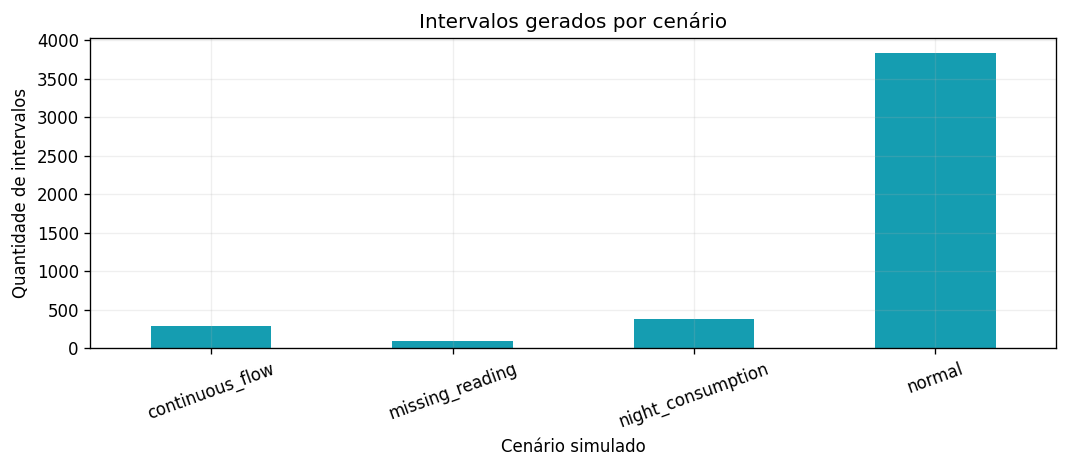

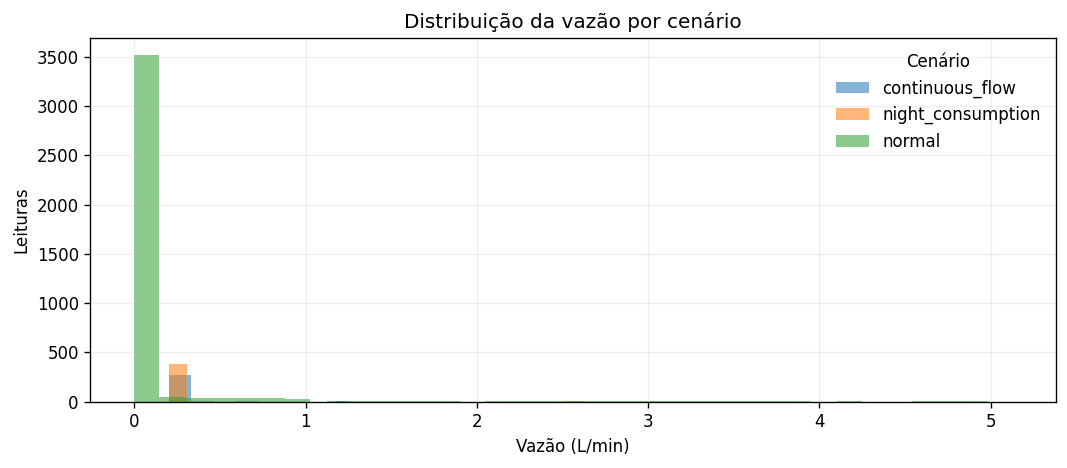

Cobertura: 97.9%


In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
raw["scenario_label"].value_counts().sort_index().plot(kind="bar", color="#159db1", ax=ax)
ax.set(title="Intervalos gerados por cenário", xlabel="Cenário simulado", ylabel="Quantidade de intervalos")
ax.tick_params(axis="x", rotation=20)
fig.tight_layout(); fig.savefig(FIGURES_DIR / "01-cenarios-gerados.png", bbox_inches="tight"); plt.show()

valid = raw.loc[raw["reading_present"] == 1].copy()
valid["flow_rate_liters_minute"] = pd.to_numeric(valid["flow_rate_liters_minute"])
fig, ax = plt.subplots(figsize=(9, 4))
for scenario, group in valid.groupby("scenario_label"):
    ax.hist(group["flow_rate_liters_minute"], bins=35, alpha=0.55, label=scenario)
ax.set(title="Distribuição da vazão por cenário", xlabel="Vazão (L/min)", ylabel="Leituras")
ax.legend(title="Cenário", frameon=False)
fig.tight_layout(); fig.savefig(FIGURES_DIR / "02-vazao-por-cenario.png", bbox_inches="tight"); plt.show()
print(f"Cobertura: {quality_report['row_counts']['coverage_ratio']:.1%}")

### Transformações aplicadas

O volume acumulado vira variação entre leituras consecutivas válidas; o intervalo real também é preservado. Hora e dia da semana são codificados ciclicamente no fuso local. A escala das medições é ajustada dentro do pipeline de cada treino, sem consultar o bloco de teste.

In [6]:
example = features.loc[features["volume_delta_liters"] > 0].index[0]
print("Leitura original e linha preparada, associadas pelo evento:")
display(raw.loc[raw["event_id"].eq(metadata.loc[example, "event_id"])].T)
display(features.loc[[example]])

Leitura original e linha preparada, associadas pelo evento:


,74
device_serial,AF-ML-MOCK-001
event_id,44f2f321-e462-55d7-9a40-dd36d06b8632
recorded_at,2026-09-01T09:10:00Z
cumulative_volume_liters,1003.88
flow_rate_liters_minute,0.776
battery_percent,95.0
signal_dbm,-58.0
firmware_version,bench-sim-1
reading_present,1
scenario_label,normal


,flow_rate_liters_minute,volume_delta_liters,elapsed_minutes,local_hour_sin,local_hour_cos,local_weekday_sin,local_weekday_cos
73,0.776,3.88,5.0,0.999048,-0.043619,0.781831,0.62349


O volume do intervalo vem da diferença entre contadores acumulados, e a duração vem dos horários observados. As lacunas continuam visíveis no tempo entre leituras. Horário e dia codificados ficam no contrato dos dados preparados. O classificador usa apenas vazão, variação de volume e duração para reduzir a dependência do calendário simulado.

In [7]:
features.describe().T

,count,mean,std,min,25%,50%,75%,max
flow_rate_liters_minute,4511.0,0.126131,0.474944,0.000000,0.000000,0.000000,0.000000,5.126000
volume_delta_liters,4511.0,0.651666,2.589523,0.000000,0.000000,0.000000,0.000000,67.880000
elapsed_minutes,4511.0,5.106407,3.572155,5.000000,5.000000,5.000000,5.000000,125.000000
local_hour_sin,4511.0,0.005223,0.713516,-1.000000,-0.722364,0.043619,0.722364,1.000000
local_hour_cos,4511.0,0.020159,0.700487,-1.000000,-0.675590,0.021815,0.722364,1.000000
local_weekday_sin,4511.0,0.110134,0.721178,-0.974928,-0.607858,0.000000,0.781831,0.974928
local_weekday_cos,4511.0,0.029305,0.683471,-0.900969,-0.561745,-0.222521,0.623490,1.000000


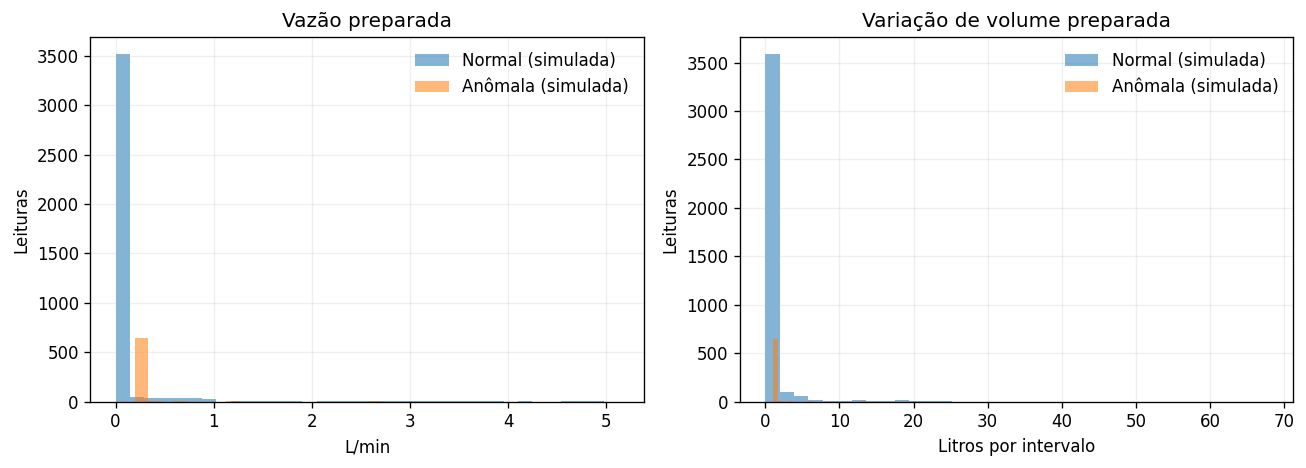

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for label, group in features.assign(anomaly_label=labels["anomaly_label"]).groupby("anomaly_label"):
    name = "Anômala (simulada)" if label else "Normal (simulada)"
    axes[0].hist(group["flow_rate_liters_minute"], bins=35, alpha=0.55, label=name)
    axes[1].hist(group["volume_delta_liters"], bins=35, alpha=0.55, label=name)
axes[0].set(title="Vazão preparada", xlabel="L/min", ylabel="Leituras")
axes[1].set(title="Variação de volume preparada", xlabel="Litros por intervalo", ylabel="Leituras")
for ax in axes: ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIGURES_DIR / "03-features-por-classe.png", bbox_inches="tight"); plt.show()

## 2. Divisão temporal, treino e seleção

Esta seção lê uma execução de referência do Compose. O notebook usa seu relatório e seu artefato para reproduzir a avaliação.

### Por que a validação cruzada é temporal?

As três divisões do TimeSeriesSplit treinam com leituras anteriores e validam com as posteriores. K-fold convencional, k-fold estratificado e Leave-One-Out podem colocar leituras futuras ou quase vizinhas da amostra avaliada no treino. Como as leituras são correlacionadas no tempo, isso pode inflar as métricas. As divisões têm uma separação de 12 amostras. Os três classificadores usam apenas vazão, delta de volume e duração, com escala ajustada no treino de cada divisão. As colunas de calendário são preservadas nos arquivos e excluídas dentro dos pipelines. A busca prefere uma configuração simples dentro de um erro padrão da melhor AP. O perfil deslocado usado no ajuste final é anterior ao teste principal.

O próximo gráfico compara a capacidade de ordenar as anomalias pela pontuação do modelo nos dois perfis. Uma queda de average precision na rotina alterada indica maior sensibilidade à mudança simulada.

In [9]:
metrics_path = TRAINING_DIR / "metrics.json"
split_path = TRAINING_DIR / "split_manifest.json"
model_path = TRAINING_DIR / "best_model.joblib"
missing = [p for p in (metrics_path, split_path, model_path) if not p.is_file()]
if missing:
    raise FileNotFoundError("Artefatos de treinamento ausentes. Inicie docker compose up --build e execute novamente.")
metrics = json.loads(metrics_path.read_text(encoding="utf-8"))
split_manifest = json.loads(split_path.read_text(encoding="utf-8"))
fingerprint = hashlib.sha256()
for path in (PREPARED_DIR / "features.csv", PREPARED_DIR / "labels.csv", PREPARED_DIR / "metadata.csv"):
    fingerprint.update(path.read_bytes())
if fingerprint.hexdigest() != metrics["training_data_sha256"]:
    raise ValueError("A série preparada não corresponde aos dados do modelo treinado.")
if hashlib.sha256(model_path.read_bytes()).hexdigest() != metrics["model_sha256"]:
    raise ValueError("O artefato não corresponde ao relatório de treinamento.")
selected_name = metrics["selected_model"]
comparison = pd.DataFrame({name: {
    "Validação temporal": result["validation"]["average_precision"],
    "Rotina alterada": result["generalization_validation"]["average_precision"] if result.get("generalization_validation") else np.nan,
    "Pontuação de seleção": metrics["selection_scores"][name],
} for name, result in metrics["candidates"].items()}).T.sort_values("Pontuação de seleção", ascending=False)
comparison.rename_axis("Modelo").reset_index()

,Modelo,Validação temporal,Rotina alterada,Pontuação de seleção
0,knn,0.983723,0.890866,0.937295
1,decision_tree,0.976658,0.178762,0.577710
2,random_forest,0.976658,0.178735,0.577697
3,dummy_prior,0.148936,0.180669,0.164803


In [10]:
display(pd.Series({
    "Modelo selecionado": selected_name,
    "Critério de seleção": metrics["selection_metric"],
    "Experimento MLflow": metrics["mlflow_experiment_id"],
    "SHA-256 do modelo": metrics["model_sha256"],
    "SHA-256 dos dados preparados": metrics["training_data_sha256"],
}, name="Execução de referência").to_frame())
display(pd.DataFrame({
    "Partição": ["Treino", "Validação", "Teste"],
    "Início local": [split_manifest[key] for key in ("start_local", "train_end_local", "validation_end_local")],
    "Amostras": [metrics["split_counts"][key] for key in ("train", "validation", "test")],
}))
display(pd.Series(metrics["search"], name="Busca").to_frame())

,Execução de referência
Modelo selecionado,knn
Critério de seleção,mean_average_precision_across_temporal_and_shi...
Experimento MLflow,1
SHA-256 do modelo,23630562eae4bb5e12603090f4b8380791be0b4a88f170...
SHA-256 dos dados preparados,65822018e7e155791ad47e2246d02c68c984f7150ea7b0...


,Partição,Início local,Amostras
0,Treino,2026-09-01T00:00:00-03:00,2255
1,Validação,2026-09-09T00:00:00-03:00,1128
2,Teste,2026-09-13T00:00:00-03:00,1128


,Busca
folds_per_candidate,3
gap_samples,12
iterations_per_model,4
parameter_selection,simplest_within_one_standard_error
seed,42
strategy,random_parameter_sampling_with_time_series_cro...
total_candidate_fits,36


In [11]:
import sqlite3

db = root / "data" / "ml" / "mlflow-server" / "mlflow.db"
if metrics.get("mlflow_run_id"):
    print("ID da execução registrada no relatório:", metrics["mlflow_run_id"])
elif db.is_file():
    with sqlite3.connect(db.as_uri() + "?mode=ro", uri=True) as connection:
        runs = pd.read_sql_query("""
            SELECT r.run_uuid AS run_id, r.start_time
            FROM runs r
            JOIN params model ON model.run_uuid = r.run_uuid AND model.key = 'model_sha256'
            JOIN params dados ON dados.run_uuid = r.run_uuid AND dados.key = 'data_sha256'
            WHERE r.experiment_id = ? AND r.status = 'FINISHED'
              AND model.value = ? AND dados.value = ?
            ORDER BY r.start_time DESC
        """, connection, params=(metrics["mlflow_experiment_id"],
                                 metrics["model_sha256"], metrics["training_data_sha256"]))
    if not runs.empty:
        runs["inicio_utc"] = pd.to_datetime(runs.pop("start_time"), unit="ms", utc=True)
        display(runs)
        print("Registro compatível mais recente:", runs.iloc[0]["run_id"])
    else:
        print("Nenhum registro local corresponde aos dois hashes.")
else:
    print("Banco local do MLflow ausente. Consulte o experimento pelos hashes acima.")

ID da execução registrada no relatório: beaa90e175f04d019175ef1e6c4d2015


No MLflow, use o identificador do experimento e o hash do artefato selecionado para localizar os registros. O DAG do Airflow orquestra geração, preparação e treino de candidato em uma execução separada. Os números exibidos aqui são da execução do Compose identificada na tabela.

,Parâmetros escolhidos
decision_tree,"{'model__max_depth': 2, 'model__min_samples_le..."
dummy_prior,{}
knn,{'model__neighbor_fraction': 0.025}
random_forest,"{'model__max_depth': 2, 'model__min_samples_le..."


,Modelo,fold,train_average_precision,validation_average_precision
0,decision_tree,1,0.980556,0.934210
1,decision_tree,2,0.987622,0.975198
2,decision_tree,3,0.984188,0.979592
3,knn,1,0.982915,0.943507
4,knn,2,0.990834,0.977447
5,knn,3,0.987958,0.979592
6,random_forest,1,0.980556,0.943603
7,random_forest,2,0.987500,0.974803
8,random_forest,3,0.984188,0.989691


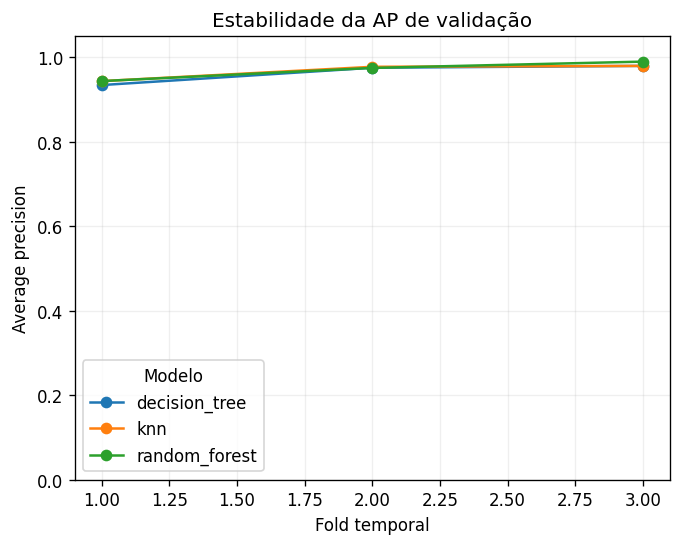

In [12]:
folds = pd.DataFrame([
    {"Modelo": name, **fold}
    for name, result in metrics["candidates"].items()
    for fold in result.get("cv_folds", [])
])
display(pd.Series({
    name: result["best_parameters"] for name, result in metrics["candidates"].items()
}, name="Parâmetros escolhidos").to_frame())
display(folds)
ax = folds.pivot(index="fold", columns="Modelo", values="validation_average_precision").plot(marker="o")
ax.set(title="Estabilidade da AP de validação", xlabel="Fold temporal", ylabel="Average precision", ylim=(0, 1.05))
plt.show()

In [13]:
from sklearn.model_selection import ParameterGrid, ParameterSampler, TimeSeriesSplit
from train_model import _models

search = metrics["search"]
trials = []
for name, (_, space) in _models(search["seed"]).items():
    sampled = ParameterSampler(space, random_state=search["seed"],
                               n_iter=min(search["iterations_per_model"], len(ParameterGrid(space))))
    for number, params in enumerate(sampled, start=1):
        trials.append({"Modelo": name, "Tentativa": number,
                       "Parâmetros": json.dumps(params, sort_keys=True)})
display(pd.DataFrame(trials))
print("Combinações reconstruídas com o espaço do trainer e a semente registrada.")

2026/11/24 19:00:17 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at C:\Users\guivr\AppData\Local\Programs\Python\Python312\Lib\site-packages\mlflow\assistant\skills\instrumenting-with-mlflow-tracing\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


,Modelo,Tentativa,Parâmetros
0,knn,1,"{""model__neighbor_fraction"": 0.01}"
1,knn,2,"{""model__neighbor_fraction"": 0.015}"
2,knn,3,"{""model__neighbor_fraction"": 0.02}"
3,knn,4,"{""model__neighbor_fraction"": 0.025}"
4,random_forest,1,"{""model__max_depth"": 2, ""model__min_samples_le..."
5,random_forest,2,"{""model__max_depth"": 2, ""model__min_samples_le..."
6,random_forest,3,"{""model__max_depth"": 3, ""model__min_samples_le..."
7,random_forest,4,"{""model__max_depth"": 3, ""model__min_samples_le..."
8,decision_tree,1,"{""model__max_depth"": 2, ""model__min_samples_le..."
9,decision_tree,2,"{""model__max_depth"": 2, ""model__min_samples_le..."


Combinações reconstruídas com o espaço do trainer e a semente registrada.


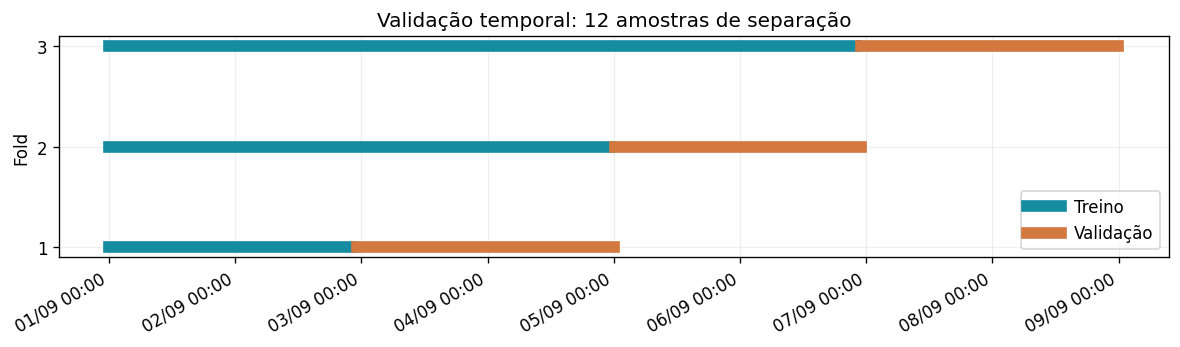

,Fold,Partição,Início,Fim
0,1,Treino,2026-09-01 00:05:00-03:00,2026-09-02 22:10:00-03:00
1,1,Validação,2026-09-02 23:15:00-03:00,2026-09-05 00:05:00-03:00
2,2,Treino,2026-09-01 00:05:00-03:00,2026-09-04 23:05:00-03:00
3,2,Validação,2026-09-05 00:10:00-03:00,2026-09-06 23:00:00-03:00
4,3,Treino,2026-09-01 00:05:00-03:00,2026-09-06 22:00:00-03:00
5,3,Validação,2026-09-06 23:05:00-03:00,2026-09-08 23:55:00-03:00


In [14]:
from matplotlib.dates import DateFormatter

dates = pd.to_datetime(metadata["recorded_at"], utc=True).dt.tz_convert(TIMEZONE)
train_dates = dates[dates < pd.Timestamp(split_manifest["train_end_local"])].reset_index(drop=True)
assert len(train_dates) == metrics["split_counts"]["train"]
splitter = TimeSeriesSplit(n_splits=search["folds_per_candidate"], gap=search["gap_samples"])
fig, ax = plt.subplots(figsize=(10, 3))
bounds = []
for fold, (fit, val) in enumerate(splitter.split(train_dates), start=1):
    for indices, label, color in ((fit, "Treino", "#168ca1"), (val, "Validação", "#d3783f")):
        start, end = train_dates.iloc[[indices[0], indices[-1]]]
        ax.plot([start, end], [fold, fold], linewidth=7, color=color,
                label=label if fold == 1 else None)
        bounds.append({"Fold": fold, "Partição": label, "Início": start, "Fim": end})
ax.xaxis.set_major_formatter(DateFormatter("%d/%m %H:%M", tz=ZoneInfo(TIMEZONE)))
ax.set(yticks=range(1, search["folds_per_candidate"] + 1), ylabel="Fold",
       title=f"Validação temporal: {search['gap_samples']} amostras de separação")
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "09-limites-folds.png", bbox_inches="tight")
plt.show()
display(pd.DataFrame(bounds))

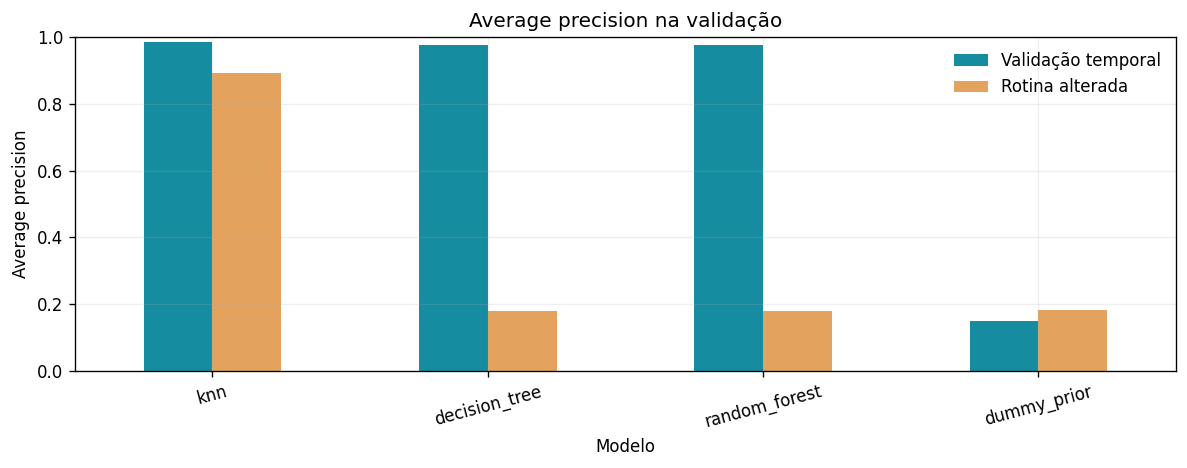

Modelo selecionado: knn


In [15]:
ax = comparison[["Validação temporal", "Rotina alterada"]].plot(kind="bar", figsize=(10, 4), color=["#168ca1", "#e3a35f"])
ax.set(title="Average precision na validação", xlabel="Modelo", ylabel="Average precision", ylim=(0, 1))
ax.tick_params(axis="x", rotation=15); ax.legend(frameon=False)
fig = ax.get_figure(); fig.tight_layout(); fig.savefig(FIGURES_DIR / "04-comparacao-modelos.png", bbox_inches="tight"); plt.show()
print(f"Modelo selecionado: {selected_name}")

## 3. Avaliação, erros e mudança de rotina

### Matrizes de confusão dos quatro candidatos

No bloco de validação temporal, compare as células fora da diagonal. Falsos positivos são janelas normais que o modelo sinalizou. Falsos negativos são janelas com anomalia simulada que ele deixou passar. A tela de alertas aplica critérios adicionais para criar avisos. As porcentagens são calculadas por classe observada para facilitar a comparação mesmo quando há poucas anomalias.

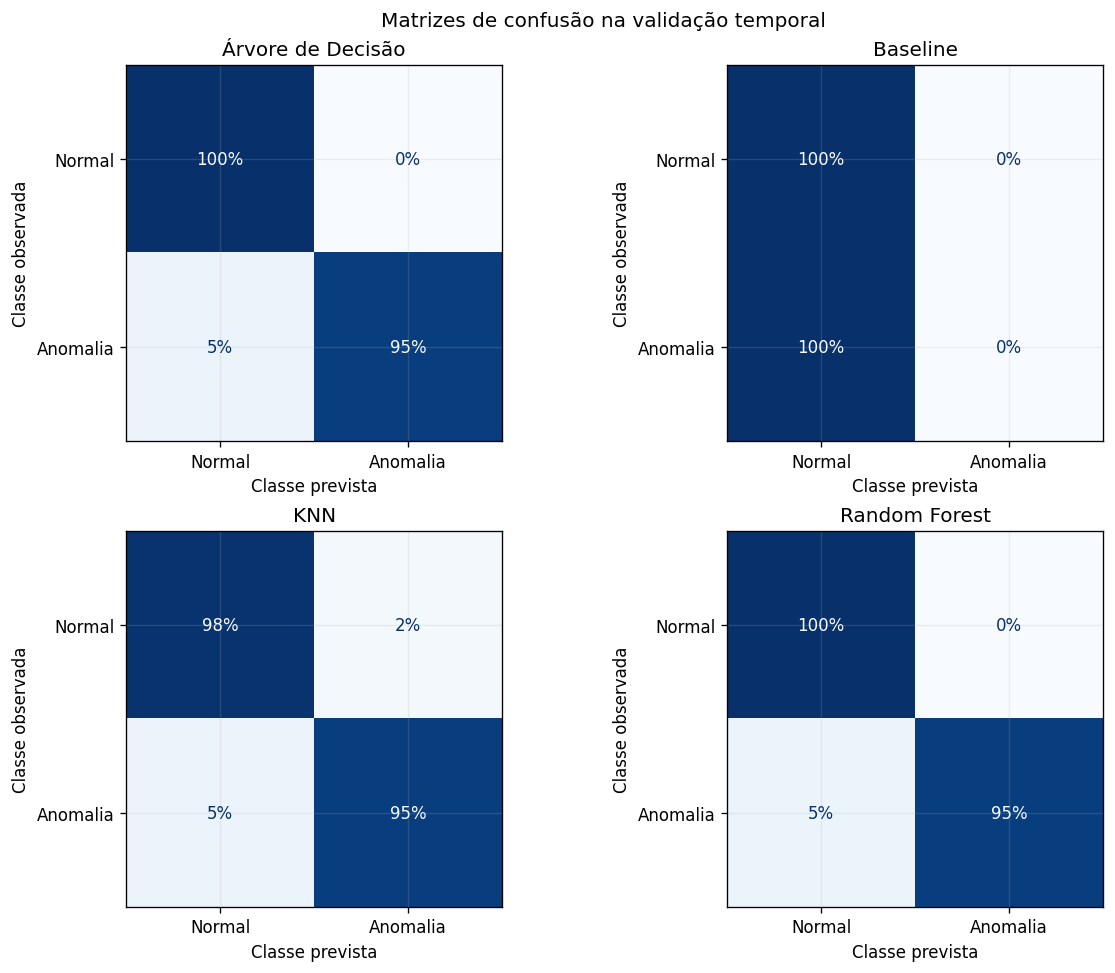

In [16]:
from sklearn.metrics import ConfusionMatrixDisplay

names = {"knn": "KNN", "decision_tree": "Árvore de Decisão",
         "random_forest": "Random Forest", "dummy_prior": "Baseline"}
fig, axes = plt.subplots(2, 2, figsize=(10, 8), layout="constrained")
for ax, (name, result) in zip(axes.flat, metrics["candidates"].items(), strict=True):
    counts = np.asarray(result["validation"]["confusion_matrix"])
    rates = counts / counts.sum(axis=1, keepdims=True)
    matrix_display = ConfusionMatrixDisplay(rates, display_labels=["Normal", "Anomalia"])
    matrix_display.plot(ax=ax, cmap="Blues", colorbar=False, values_format=".0%",
                 im_kw={"vmin": 0, "vmax": 1})
    ax.set(title=names[name], xlabel="Classe prevista", ylabel="Classe observada")
fig.suptitle("Matrizes de confusão na validação temporal")
fig.savefig(FIGURES_DIR / "07-matrizes-validacao.png", dpi=150)
plt.show()

### Precisão e recall com mudança de rotina

O limiar de 0,5 é o mesmo nos dois perfis. Se o recall cai, uma parcela maior das janelas com anomalia simulada passa sem sinalização. Se a precisão cai, uma parcela maior das janelas sinalizadas era normal.

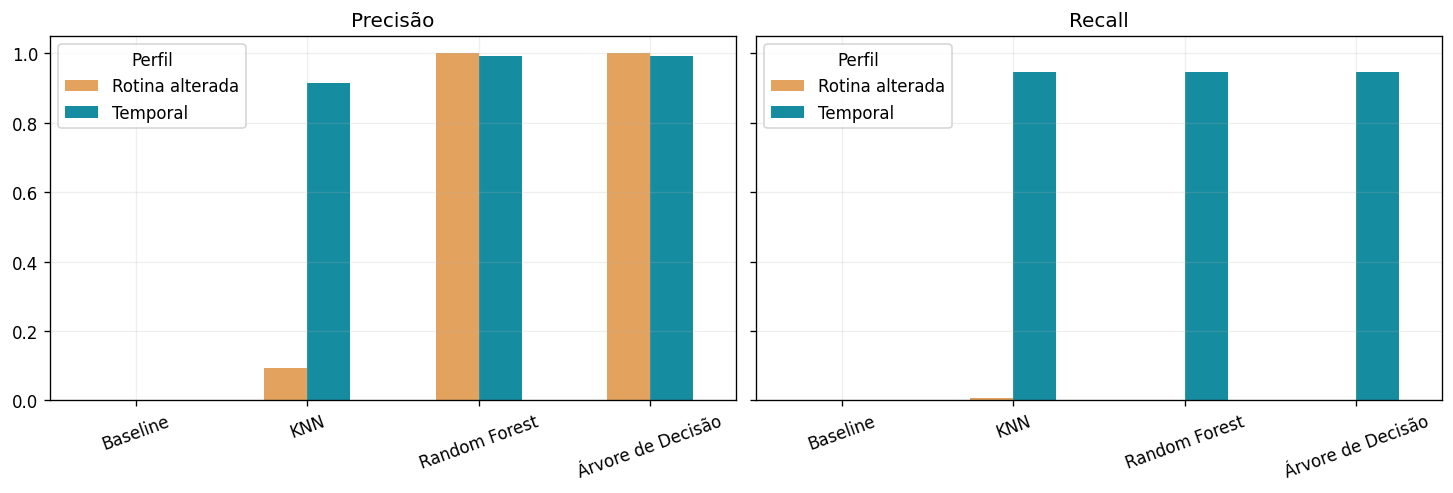

In [17]:
records = []
for name, result in metrics["candidates"].items():
    for profile, key in [("Temporal", "validation"), ("Rotina alterada", "generalization_validation")]:
        if result[key] is not None:
            records.append({"Modelo": names[name], "Perfil": profile,
                            "Precisão": result[key]["precision"], "Recall": result[key]["recall"]})
scores = pd.DataFrame(records)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained", sharey=True)
for ax, metric in zip(axes, ["Precisão", "Recall"], strict=True):
    scores.pivot(index="Modelo", columns="Perfil", values=metric).plot.bar(
        ax=ax, rot=20, color=["#e3a35f", "#168ca1"]
    )
    ax.set(title=metric, xlabel="", ylim=(0, 1.05))
fig.savefig(FIGURES_DIR / "08-precisao-recall-candidatos.png", dpi=150)
plt.show()

### Teste cronológico reservado

A matriz usa o limiar de 0,5 adotado pelo pipeline. Precisão-recall ajuda a observar a relação entre encontrar positivos e evitar falsos positivos; ROC/AUC resume a separação das classes em vários limiares. Métricas com dados simulados não provam desempenho em consumo real.

In [18]:
test_start = datetime.fromisoformat(split_manifest["validation_end_local"]).astimezone(ZoneInfo("UTC"))
timestamps = pd.to_datetime(metadata["recorded_at"], utc=True)
test_mask = timestamps >= pd.Timestamp(test_start)
X_test = features.loc[test_mask].to_numpy(dtype=float)
y_test = labels.loc[test_mask, "anomaly_label"].to_numpy(dtype=int)
if len(y_test) == 0 or set(y_test) != {0, 1}:
    raise ValueError("A partição de teste precisa conter as duas classes.")
model = load(model_path)
probabilities = model.predict_proba(X_test)[:, 1]
predictions = (probabilities >= metrics["threshold"]).astype(int)
cm = confusion_matrix(y_test, predictions, labels=[0, 1])
pr_auc = average_precision_score(y_test, probabilities)
roc_auc = roc_auc_score(y_test, probabilities)
print(f"Amostras de teste: {len(y_test)} | AP: {pr_auc:.3f} | ROC AUC: {roc_auc:.3f}")

Amostras de teste: 1128 | AP: 0.994 | ROC AUC: 0.999


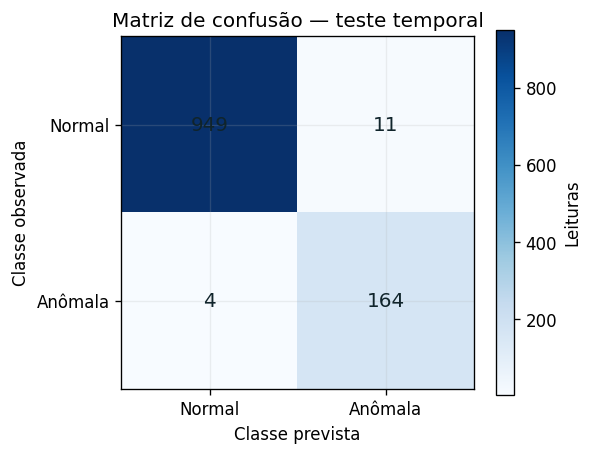

In [19]:
fig, ax = plt.subplots(figsize=(5, 4))
image = ax.imshow(cm, cmap="Blues")
ax.set(title="Matriz de confusão — teste temporal", xlabel="Classe prevista", ylabel="Classe observada")
ax.set_xticks([0, 1], labels=["Normal", "Anômala"]); ax.set_yticks([0, 1], labels=["Normal", "Anômala"])
for row in range(2):
    for col in range(2): ax.text(col, row, str(cm[row, col]), ha="center", va="center", color="#10242b", fontsize=12)
fig.colorbar(image, ax=ax, label="Leituras"); fig.tight_layout()
fig.savefig(FIGURES_DIR / "05-matriz-confusao.png", bbox_inches="tight"); plt.show()

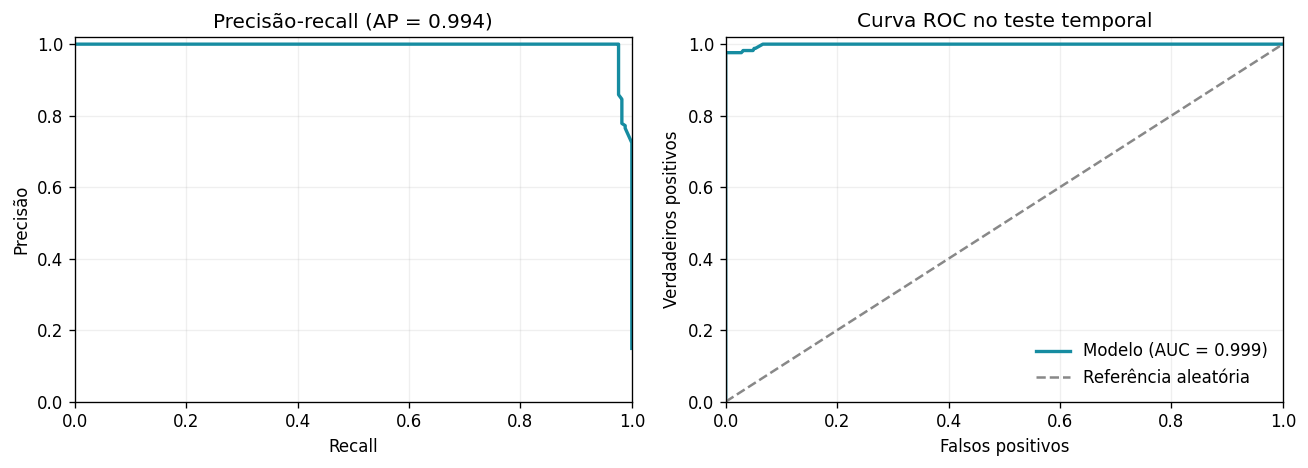

In [20]:
precision, recall, _ = precision_recall_curve(y_test, probabilities)
fpr, tpr, _ = roc_curve(y_test, probabilities)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(recall, precision, color="#168ca1", linewidth=2)
axes[0].set(title=f"Precisão-recall (AP = {pr_auc:.3f})", xlabel="Recall", ylabel="Precisão", xlim=(0, 1), ylim=(0, 1.02))
axes[1].plot(fpr, tpr, color="#168ca1", linewidth=2, label=f"Modelo (AUC = {roc_auc:.3f})")
axes[1].plot([0, 1], [0, 1], "--", color="#888888", label="Referência aleatória")
axes[1].set(title="Curva ROC no teste temporal", xlabel="Falsos positivos", ylabel="Verdadeiros positivos", xlim=(0, 1), ylim=(0, 1.02))
axes[1].legend(frameon=False); fig.tight_layout()
fig.savefig(FIGURES_DIR / "06-curvas-precisao-recall-roc.png", bbox_inches="tight"); plt.show()

In [21]:
tn, fp, fn, tp = cm.ravel()
print(f"No teste reservado, {fp} de {tn + fp} janelas normais foram sinalizadas.")
print(f"Entre {tp + fn} anomalias simuladas, {fn} passaram despercebidas.")
candidate = metrics["candidates"][selected_name]
profiles = {
    "Candidato: validação padrão": candidate["validation"],
    "Candidato: rotina alterada": candidate["generalization_validation"],
    "Modelo final: teste cronológico": metrics["test_evaluation"][selected_name],
    "Modelo final: teste de estresse": (metrics.get("stress_test_evaluation") or {}).get("selected_model"),
}
display(pd.DataFrame({
    profile: {key: result[key] for key in ("average_precision", "precision", "recall", "f1")}
    for profile, result in profiles.items() if result
}).T)
print(f"Gap médio treino/validação nos folds: {candidate['cv_generalization_gap']:+.3f}")
print(f"Desvio padrão da AP de validação nos folds: {candidate['cv_validation_average_precision_std']:.3f}")

No teste reservado, 11 de 960 janelas normais foram sinalizadas.
Entre 168 anomalias simuladas, 4 passaram despercebidas.


,average_precision,precision,recall,f1
Candidato: validação padrão,0.983723,0.913793,0.946429,0.929825
Candidato: rotina alterada,0.890866,0.092308,0.007362,0.013636
Modelo final: teste cronológico,0.994444,0.937143,0.976190,0.956268
Modelo final: teste de estresse,0.928843,0.926966,0.917942,0.922432


Gap médio treino/validação nos folds: +0.020
Desvio padrão da AP de validação nos folds: 0.017


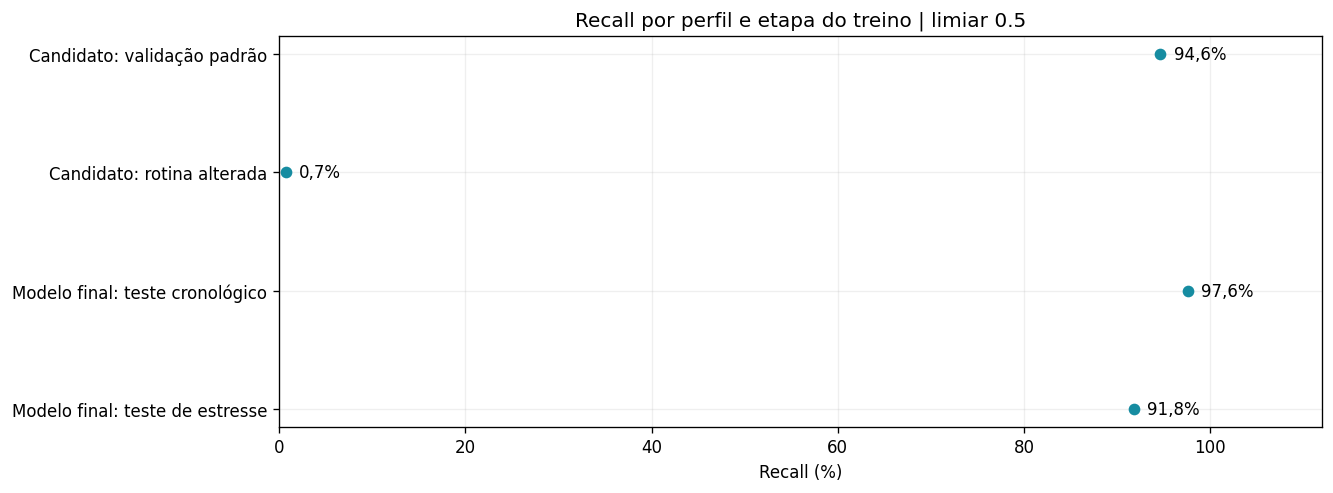

In [22]:
recalls = {profile: result["recall"] for profile, result in profiles.items() if result}
fig, ax = plt.subplots(figsize=(11, 4), layout="constrained")
for i, (profile, value) in enumerate(recalls.items()):
    ax.plot(value * 100, i, "o", color="#168ca1")
    ax.annotate(f"{value:.1%}".replace(".", ","), (value * 100, i),
                xytext=(8, 0), textcoords="offset points", va="center")
ax.set(yticks=range(len(recalls)), yticklabels=list(recalls), xlim=(0, 112),
       xlabel="Recall (%)", title=f"Recall por perfil e etapa do treino | limiar {metrics['threshold']}")
ax.invert_yaxis()
fig.savefig(FIGURES_DIR / "10-recall-por-perfil.png", dpi=150)
plt.show()

### Leitura dos resultados salvos

Antes do ajuste final, o mesmo candidato KNN passou de 94,6% de recall no perfil padrão para 0,7% na rotina alterada, com limiar de 0,5. No segundo perfil, detectou 6 das 815 anomalias e sinalizou 59 janelas normais. Árvore de Decisão e Random Forest detectaram uma anomalia cada, com AP ligeiramente abaixo da referência de prevalência. A AP do KNN de 0,891 indica uma boa ordenação relativa nesse perfil, mesmo com poucas detecções no limiar escolhido.

O ajuste final incluiu dados da rotina alterada. Depois desse ajuste, o KNN alcançou 97,6% de recall no teste cronológico reservado e 91,8% no teste de estresse separado. São avaliações do artefato final, em conjuntos distintos dos usados para seleção.

As métricas contam janelas individuais. O sistema exige previsões consecutivas para gerar um aviso de ML. A avaliação por episódio precisaria medir avisos falsos, episódios perdidos e tempo até o aviso. A série combina vazões calibradas em bancada com rotinas e rótulos simulados. A validação residencial exigiria medições independentes com eventos verificados.

## 4. Inferência, integração e critérios de entrega

O exemplo abaixo prepara uma série simulada com outra semente e usa a mesma CLI de inferência do projeto. A previsão lê somente as medições preparadas e os metadados. No sistema integrado, o worker processa as leituras persistidas, registra as inferências e a API as disponibiliza ao painel. Avisos de ML exigem uma sequência de janelas positivas. As regras de consumo continuam funcionando separadamente.

In [23]:
from predict_model import predict

example_dir = DATA_DIR / "inference-example"
example_raw = example_dir / "raw.csv"
example_prepared = example_dir / "prepared"
example_predictions = example_dir / "predictions"
build(None, example_raw, calibration=DEFAULT_CALIBRATION, seed=99,
      start=datetime.fromisoformat("2026-09-17T00:00:00-03:00").astimezone(UTC),
      days=4, interval_minutes=5, timezone=TIMEZONE)
prepare(example_raw, example_prepared, TIMEZONE)
predict(example_prepared / "features.csv", example_prepared / "metadata.csv",
        example_prepared / "preparation_manifest.json", model_path, metrics_path,
        example_predictions)
pd.read_csv(example_predictions / "predictions.csv").head()

{"inference_data_sha256": "cf927bd2eaaaf60b0d0125082dcc4f8464a5f8e01567a06e19d709d025bd88a1", "limitation": "predictions describe generated scenarios and are not validated on real telemetry", "model_version": "23630562eae4bb5e12603090f4b8380791be0b4a88f170168646856fe827c671", "predicted_anomalies": 177, "prediction_count": 1127, "prediction_file": "predictions.csv", "selected_model": "knn", "status": "offline_simulated_inference", "threshold": 0.5, "timezone": "America/Sao_Paulo", "training_data_sha256": "65822018e7e155791ad47e2246d02c68c984f7150ea7b0dd89c24c167436bb78"}


,event_id,recorded_at,predicted_anomaly,anomaly_probability,model_version,feature_effects_json
0,73d03045-9bac-5e2e-afb8-a25cb97c1f05,2026-09-17T03:05:00Z,0,0.0,23630562eae4bb5e12603090f4b8380791be0b4a88f170...,"{""elapsed_minutes"": 0.0, ""flow_rate_liters_min..."
1,adb7e5d7-a801-5001-ac1f-58bd2771d427,2026-09-17T03:10:00Z,0,0.0,23630562eae4bb5e12603090f4b8380791be0b4a88f170...,"{""elapsed_minutes"": 0.0, ""flow_rate_liters_min..."
2,61bc5e9a-c082-515e-af9b-8f335dd5fd12,2026-09-17T03:15:00Z,0,0.0,23630562eae4bb5e12603090f4b8380791be0b4a88f170...,"{""elapsed_minutes"": 0.0, ""flow_rate_liters_min..."
3,c8a98df3-5bdc-5300-89c8-e4a5c12719de,2026-09-17T03:20:00Z,0,0.0,23630562eae4bb5e12603090f4b8380791be0b4a88f170...,"{""elapsed_minutes"": 0.0, ""flow_rate_liters_min..."
4,a849d411-973c-548b-9763-96eec7de3a4c,2026-09-17T03:25:00Z,0,0.0,23630562eae4bb5e12603090f4b8380791be0b4a88f170...,"{""elapsed_minutes"": 0.0, ""flow_rate_liters_min..."


### Avaliação adicional por janela e episódio

O limiar experimental maximiza F1 em uma série híbrida reservada para essa escolha. O desempenho é medido depois, em duas séries com outras sementes e períodos. O limiar do serviço continua em 0,5. A simulação de avisos usa dois positivos consecutivos dentro da tolerância do worker. Cada sequência ganha no máximo um aviso. Episódios rotulados são agrupados por continuidade e por tipo. A simulação cobre a regra temporal; persistência e concorrência pertencem ao worker integrado.

In [24]:
from sklearn.metrics import precision_recall_fscore_support
from train_model import _load_dataset

models = {selected_name: model}
for name in metrics["candidate_holdout_evaluation"]:
    path = TRAINING_DIR / "candidate-models" / f"{name}.joblib"
    if name != selected_name and path.is_file():
        models[name] = load(path)

def score_series(seed, start, profile):
    directory = DATA_DIR / "robustness" / str(seed)
    raw_file = directory / "raw.csv"
    prepared = directory / "prepared"
    build(None, raw_file, calibration=DEFAULT_CALIBRATION, seed=seed,
          start=datetime.fromisoformat(start), days=4, interval_minutes=5,
          timezone=TIMEZONE, profile=profile)
    prepare(raw_file, prepared, TIMEZONE)
    x, y, dates, fingerprint = _load_dataset(
        prepared / "features.csv", prepared / "labels.csv", prepared / "metadata.csv", TIMEZONE
    )
    frame = pd.read_csv(prepared / "labels.csv")
    frame["time"] = pd.to_datetime(dates, utc=True)
    frame["elapsed"] = x[:, features.columns.get_loc("elapsed_minutes")]
    for name, estimator in models.items():
        frame[name] = estimator.predict_proba(x)[:, 1]
    frame.attrs["sha256"] = fingerprint
    return frame

def window_metrics(frame, threshold):
    predicted = frame["score"] >= threshold
    precision, recall, f1, _ = precision_recall_fscore_support(
        frame["anomaly_label"], predicted, average="binary", zero_division=0
    )
    return {"Precisão": precision, "Recall": recall, "F1": f1,
            "Falsos positivos": int((predicted & frame["anomaly_label"].eq(0)).sum())}

def episode_metrics(frame, threshold):
    seconds = frame["time"].diff().dt.total_seconds()
    adjacent = seconds.le(301)
    positive = frame["score"].ge(threshold)
    paired = positive & positive.shift(fill_value=False) & seconds.le(frame["elapsed"] * 60 + 1)
    starts = positive & ~paired
    groups = starts.cumsum()
    alert_times = frame.loc[paired].groupby(groups[paired])["time"].first()
    truth = frame["anomaly_label"].eq(1)
    boundaries = ~truth.shift(fill_value=False) | ~adjacent | frame["scenario_label"].ne(frame["scenario_label"].shift())
    episodes = frame.loc[truth].groupby(boundaries.cumsum()[truth])["time"].agg(["min", "max"])
    delays = []
    matched = set()
    for episode in episodes.itertuples():
        hits = alert_times[alert_times.between(episode.min, episode.max)]
        if not hits.empty:
            delays.append((hits.iloc[0] - episode.min).total_seconds() / 60)
            matched.update(hits.index)
    return {"Episódios": len(episodes), "Detectados": len(delays),
            "Perdidos": len(episodes) - len(delays), "Avisos falsos": len(alert_times) - len(matched),
            "Atraso mediano (min)": float(np.median(delays)) if delays else None}

validation = score_series(701, "2026-12-01T00:00:00-03:00", "shifted")
thresholds = sorted(set(np.linspace(0.05, 0.95, 19)) | {metrics["threshold"]})
chosen = {}
for model_name in models:
    trial = validation.assign(score=validation[model_name])
    sweep = pd.DataFrame([{"Limiar": t, **window_metrics(trial, t)} for t in thresholds])
    chosen[model_name] = float(sweep.sort_values(["F1", "Limiar"], ascending=False).iloc[0]["Limiar"])
    print(model_name, "limiar experimental:", chosen[model_name])
    display(sweep.round(3))
print("Hash da validação do limiar:", validation.attrs["sha256"])
rows = []
scenarios = []
for seed, start, profile in ((811, "2027-01-01T00:00:00-03:00", "shifted"),
                              (907, "2027-02-01T00:00:00-03:00", "stress")):
    unseen = score_series(seed, start, profile)
    print(f"Teste {profile}, semente {seed}: {unseen.attrs['sha256']}")
    for model_name in models:
        scored = unseen.assign(score=unseen[model_name])
        for name, threshold in (("Operacional", metrics["threshold"]), ("Experimental", chosen[model_name])):
            rows.append({"Modelo": model_name, "Perfil": profile, "Semente": seed,
                         "Política": name, "Limiar": threshold,
                         **window_metrics(scored, threshold), **episode_metrics(scored, threshold)})
        for scenario, group in scored.groupby("scenario_label"):
            scenarios.append({"Modelo": model_name, "Perfil": profile, "Cenário": scenario,
                              "Janelas": len(group), "Sinalizadas": int(group["score"].ge(metrics["threshold"]).sum())})
display(pd.DataFrame(rows).round(3))
display(pd.DataFrame(scenarios))

knn limiar experimental: 0.95


,Limiar,Precisão,Recall,F1,Falsos positivos
0,0.05,0.606,1.000,0.755,132
1,0.10,0.637,0.985,0.774,114
2,0.15,0.795,0.956,0.868,50
3,0.20,0.874,0.926,0.900,27
4,0.25,0.879,0.926,0.902,26
5,0.30,0.883,0.926,0.904,25
6,0.35,0.882,0.921,0.901,25
7,0.40,0.903,0.921,0.912,20
8,0.45,0.903,0.921,0.912,20
9,0.50,0.908,0.921,0.914,19


decision_tree limiar experimental: 0.95


,Limiar,Precisão,Recall,F1,Falsos positivos
0,0.05,0.606,1.000,0.755,132
1,0.10,0.606,1.000,0.755,132
2,0.15,0.606,1.000,0.755,132
3,0.20,0.606,1.000,0.755,132
4,0.25,0.606,1.000,0.755,132
5,0.30,0.606,1.000,0.755,132
6,0.35,0.606,1.000,0.755,132
7,0.40,0.606,1.000,0.755,132
8,0.45,0.958,0.906,0.932,8
9,0.50,0.958,0.906,0.932,8


random_forest limiar experimental: 0.95


,Limiar,Precisão,Recall,F1,Falsos positivos
0,0.05,0.606,1.000,0.755,132
1,0.10,0.606,1.000,0.755,132
2,0.15,0.606,1.000,0.755,132
3,0.20,0.606,1.000,0.755,132
4,0.25,0.606,1.000,0.755,132
5,0.30,0.606,1.000,0.755,132
6,0.35,0.606,1.000,0.755,132
7,0.40,0.606,1.000,0.755,132
8,0.45,0.949,0.911,0.930,10
9,0.50,0.949,0.911,0.930,10


Hash da validação do limiar: 590f6eb9fa7fd9ab27b9eb3e50e91a4660eb6be47117c33881ae76076d2073a2


Teste shifted, semente 811: 0003ba48d7bf693259aa8f8c66c27d4001955b8bad942e252d66b8af2cf1db42


Teste stress, semente 907: 09f27f96ed11e335f951be8996c2098c23602300705542996f11f5bb90263485


,Modelo,Perfil,Semente,Política,Limiar,Precisão,Recall,F1,Falsos positivos,Episódios,Detectados,Perdidos,Avisos falsos,Atraso mediano (min)
0,knn,shifted,811,Operacional,0.50,0.910,0.901,0.906,18,3,3,0,0,5.0
1,knn,shifted,811,Experimental,0.95,0.995,0.892,0.940,1,3,3,0,0,5.0
2,decision_tree,shifted,811,Operacional,0.50,0.968,0.892,0.928,6,3,3,0,0,5.0
3,decision_tree,shifted,811,Experimental,0.95,0.968,0.892,0.928,6,3,3,0,0,5.0
4,random_forest,shifted,811,Operacional,0.50,0.963,0.892,0.926,7,3,3,0,0,5.0
5,random_forest,shifted,811,Experimental,0.95,0.968,0.892,0.928,6,3,3,0,0,5.0
6,knn,stress,907,Operacional,0.50,0.947,0.894,0.920,9,3,3,0,0,5.0
7,knn,stress,907,Experimental,0.95,0.000,0.000,0.000,4,3,0,3,0,NaN
8,decision_tree,stress,907,Operacional,0.50,0.976,0.894,0.933,4,3,3,0,0,5.0
9,decision_tree,stress,907,Experimental,0.95,0.976,0.894,0.933,4,3,3,0,0,5.0


,Modelo,Perfil,Cenário,Janelas,Sinalizadas
0,knn,shifted,continuous_flow,108,92
1,knn,shifted,night_consumption,95,91
2,knn,shifted,normal,924,18
3,decision_tree,shifted,continuous_flow,108,91
4,decision_tree,shifted,night_consumption,95,90
5,decision_tree,shifted,normal,924,6
6,random_forest,shifted,continuous_flow,108,91
7,random_forest,shifted,night_consumption,95,90
8,random_forest,shifted,normal,924,7
9,knn,stress,continuous_flow,84,69


**Resultado da execução salva.** A escolha por F1 na validação levou o KNN a 0,95. No estresse inédito, esse limiar deixou passar os três episódios. Com 0,5, os três foram detectados na simulação. São poucos episódios e o resultado depende da série. O experimento mostra por que otimizar um limiar em um perfil isolado pode piorar outro.

Para reproduzir com outro diretório de treino, defina a variável de ambiente AQUAFLOW_NOTEBOOK_TRAINING_DIR antes de executar as células. As saídas salvas vieram de data/ml/quality-audit, com MLflow em SQLite local. A execução não foi promovida. O painel identifica cada relatório pelo ID da execução disponível no MLflow configurado para a aplicação.

### Mapa dos critérios

| Critério | Evidência |
| --- | --- |
| 4 | EDA, preparação e justificativas na seção 1. Orquestração documentada no [guia do pipeline](../docs/pipeline.md). |
| 5 e 6 | Referência por prevalência, três classificadores, métricas, gráficos e erros nas seções 2 e 3. |
| 7 e 8 | Busca de parâmetros, validação cruzada temporal, estabilidade por fold e teste sob mudança de rotina nas seções 2 e 3. |
| 9 | Inferência offline nesta seção e evidências da integração na [validação MQTT simulada](../../docs/validacao-integracao.md). |


### Gráficos para o Google Sites

Os arquivos abaixo são gerados pela execução deste notebook em `data/ml/notebook/figures/`.

| Arquivo | Legenda sugerida |
| --- | --- |
| `04-comparacao-modelos.png` | Comparação da average precision na validação temporal e com rotina alterada. A seleção considera os dois perfis. |
| `07-matrizes-validacao.png` | Matrizes dos quatro candidatos na validação temporal. Cada linha mostra a proporção dentro da classe observada. |
| `10-recall-por-perfil.png` | Percentual de anomalias simuladas detectadas por perfil, com identificação da etapa de treino e o mesmo limiar. |

Apresente os gráficos como resultados de dados simulados calibrados em bancada e associe a publicação ao hash do modelo mostrado neste notebook.

## Interpretação e limitações

- A comparação usa validação temporal e perfil de rotina alterada; o teste final permanece separado da seleção.
- A matriz de confusão mostra erros no limiar atual; as curvas mostram como a avaliação muda com outros limiares.
- Todos os dados e rótulos são artificiais e definidos pelo gerador. Os gráficos avaliam o reconhecimento desses cenários, não vazamentos reais.
- As imagens são exibidas no notebook e salvas em data/ml/notebook/figures/, diretório local ignorado pelo Git.